In [10]:
import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier

#incarcare set date proof of concept
df = pd.read_csv('../data/mock_data.csv')
print("--- Mediile indicatorilor per Scenariu (A vs B vs C) ---")
print(df.groupby('scenario')[['ai_anxiety_score', 'error_made', 'decision_abandon', 'task_completion_time_sec']].mean())

print("- Validare date initiale -")
print(f"Dimensiune set date: {df.shape[0]} randuri, {df.shape[1]} coloane")
print("Valori lipsa per coloana:", df.isnull().sum())

--- Mediile indicatorilor per Scenariu (A vs B vs C) ---
          ai_anxiety_score  error_made  decision_abandon  \
scenario                                                   
A                     2.32         0.2               0.2   
B                     3.86         0.8               0.6   
C                     4.40         0.6               0.8   

          task_completion_time_sec  
scenario                            
A                             54.0  
B                             97.0  
C                            125.0  
- Validare date initiale -
Dimensiune set date: 15 randuri, 12 coloane
Valori lipsa per coloana: user_id                     0
scenario                    0
tech_experience             0
baseline_ai_trust           0
perceived_intrusiveness     0
perceived_transparency      0
perceived_authenticity      0
spoof_alert_present         0
task_completion_time_sec    0
error_made                  0
decision_abandon            0
ai_anxiety_score            0


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier

# preprocesare si encoding
df_encoded = pd.get_dummies(df, columns=['scenario'], drop_first=True)
X = df_encoded.drop(columns=['user_id', 'decision_abandon'])
y = df_encoded['decision_abandon']

# impartirea datelor
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# antrenare Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# predictie
y_pred = rf_model.predict(X_test)

# raaport de clasifiecare
report_dict = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df.index = ['0 (Păstrează)', '1 (Abandonează)', 'accuracy', 'macro avg', 'weighted avg']

print(f"Acuratețe generală: {accuracy_score(y_test, y_pred):.2f}\n")
display(report_df.round(2))

Acuratețe generală: 1.00



,precision,recall,f1-score,support
0 (Păstrează),1.0,1.0,1.0,1.0
1 (Abandonează),1.0,1.0,1.0,2.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,3.0
weighted avg,1.0,1.0,1.0,3.0


C:\Users\Administrator\AppData\Local\Temp\ipykernel_26196\626193365.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis')


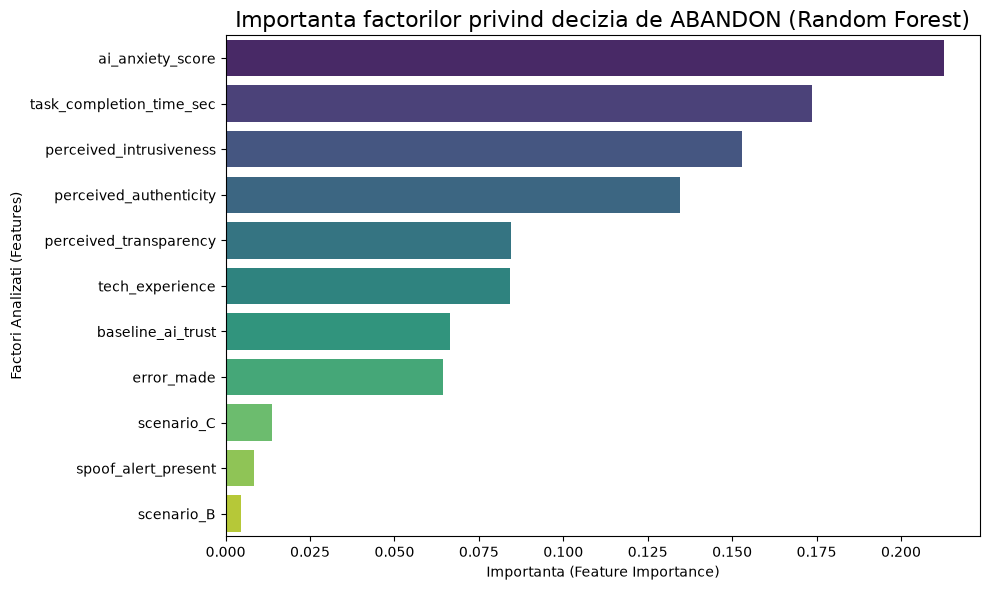

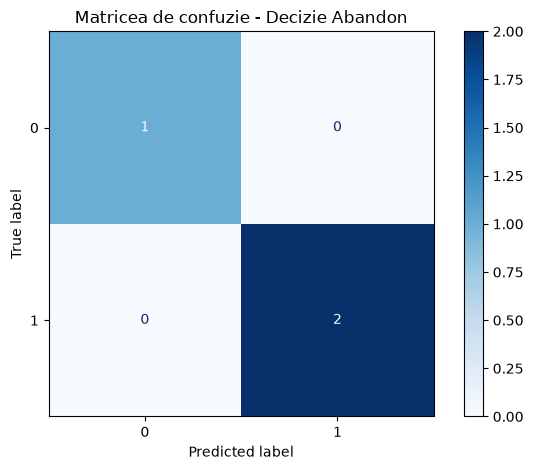

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')

plt.title('Importanta factorilor privind decizia de ABANDON (Random Forest)', fontsize=16)
plt.xlabel('Importanta (Feature Importance)', fontsize=10)
plt.ylabel('Factori Analizati (Features)', fontsize=10)
plt.tight_layout()

plt.show()

ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, cmap='Blues')
plt.title('Matricea de confuzie - Decizie Abandon')
plt.tight_layout()
plt.show()